In [1]:
!pip install -q -U transformers accelerate

import os
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"
import re
import json
import glob
import time
import subprocess
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from PIL import Image
from transformers import AutoProcessor, LlavaForConditionalGeneration

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.26.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
device: cuda


In [2]:
MODEL_NAME = "llava-hf/llava-1.5-7b-hf"
DT = torch.float16

processor = AutoProcessor.from_pretrained(MODEL_NAME)
model = LlavaForConditionalGeneration.from_pretrained(
    MODEL_NAME,
    torch_dtype=DT,
    device_map="auto",
    max_memory={0: "12GiB", 1: "12GiB"},
    attn_implementation="sdpa",
)
model.eval()
for p_ in model.parameters():
    p_.requires_grad_(False)

lm = model.model.language_model
lm_head = model.lm_head
layers = lm.layers
n_layer = model.config.text_config.num_hidden_layers
n_head = model.config.text_config.num_attention_heads
hidden_dim = model.config.text_config.hidden_size
head_dim = hidden_dim // n_head
IMAGE_TOKEN_ID = getattr(model.config, "image_token_id", None) or model.config.image_token_index
assert len(layers) == n_layer
assert model.config.text_config._attn_implementation == "sdpa"
print(n_layer, "language model layers,", n_head, "heads,", head_dim, "head dim, image token id", IMAGE_TOKEN_ID)

processor_config.json:   0%|          | 0.00/173 [00:00<?, ?B/s]

chat_template.json:   0%|          | 0.00/701 [00:00<?, ?B/s]

chat_template.jinja:   0%|          | 0.00/674 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/505 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/950 [00:00<?, ?B/s]

...

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/686 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/141 [00:00<?, ?B/s]

32 language model layers, 32 heads, 128 head dim, image token id 32000


In [3]:
INPUT = "/kaggle/input/datasets/nocturnalnerd18"
USERNAME = "nocturnalnerd18"
AMBER_IMAGE_DIR = "/kaggle/input/datasets/nocturnalnerd18/amber-hallucination/image"

SHARD = 0
N_SHARDS = 1
N_UNITS = 120
DRIVEN_TE = -1.0
SLUG = f"{USERNAME}/patch-llava-paths-s{SHARD}"
DIRECTIONS = ["noising", "denoising"]
MAX_HOURS = 9.0
PILOT_UNITS = 1
BATCH_SAVE_SIZE = 20
UPLOAD_EVERY = 2
CHECK_TOL = 0.25
YES_ID, NO_ID = 3869, 1939
TAIL_N = 4
GROUPS = ["visual", "text", "tail"]
OUT_DIR = "/kaggle/working/patch_llava_paths"
os.makedirs(OUT_DIR, exist_ok=True)

FIXED_SENDERS = [
    ("mlp", 10, -1, "visual"), ("head", 11, 26, "text"), ("head", 11, 17, "text"), ("head", 11, 9, "text"), ("head", 11, 6, "text"),
    ("head", 12, 13, "text"), ("mlp", 15, -1, "all"), ("mlp", 16, -1, "all"), ("mlp", 17, -1, "all"), ("mlp", 18, -1, "all"),
    ("head", 16, 15, "all"), ("head", 16, 0, "all"), ("mlp", 20, -1, "all"), ("mlp", 28, -1, "all"), ("mlp", 30, -1, "all"), ("mlp", 31, -1, "all"),
]
ROUTERS = [("mlp", 10, -1, "visual"), ("head", 11, 26, "text"), ("head", 11, 17, "text"), ("head", 11, 9, "text"), ("head", 11, 6, "text"), ("head", 12, 13, "text")]
SETS = {
    "direct": {"mlp": set(), "heads": False},
    "mlp_16_18": {"mlp": {16, 17, 18}, "heads": False},
    "mlp_15_20": {"mlp": set(range(15, 21)), "heads": False},
    "mlp_21_31": {"mlp": set(range(21, 32)), "heads": False},
    "mlp_28": {"mlp": {28}, "heads": False},
    "mlp_all": {"mlp": set(range(32)), "heads": False},
    "heads_all": {"mlp": set(), "heads": True},
    "total": {"mlp": set(range(32)), "heads": True},
}
SET_NAMES = list(SETS)


def load_image(path):
    return Image.open(path).convert("RGB")


def build_inputs(image, text):
    conversation = [{"role": "user", "content": [{"type": "image"}, {"type": "text", "text": text}]}]
    prompt_text = processor.apply_chat_template(conversation, add_generation_prompt=True)
    return processor(text=prompt_text, images=image, return_tensors="pt").to(model.device, DT)


def resolve_image_path(q):
    if q["question_id"].startswith("amber_"):
        return os.path.join(AMBER_IMAGE_DIR, f"{q['image_id']}.jpg")
    return None


def batch_number(path):
    return int(re.search(r"_batch_(\d+)\.pt$", path).group(1))


with open(f"{INPUT}/vlm-questions/all_questions.json") as f:
    all_questions = json.load(f)
assert len(all_questions) == 17492, "attach vlm-questions version 2"
question_by_id = {q["question_id"]: q for q in all_questions}
assert [processor.tokenizer.decode([i]).strip() for i in (YES_ID, NO_ID)] == ["Yes", "No"]

atp = {}
atp_files = sorted(glob.glob(f"{INPUT}/atp-llava-noising/**/*_batch_*.pt", recursive=True), key=lambda p: (os.path.basename(p).split("_batch_")[0], batch_number(p)))
for path in atp_files:
    for e in torch.load(path):
        if e["ok"]:
            atp[e["question_id"]] = {k: e[k] for k in (
                "question_id", "image_id", "hallucination_type", "stratum", "group", "source", "split", "sign", "seed",
                "delta_clean", "delta_corrupt", "TE", "noise_used",
            )}
print(f"atp-llava-noising: {len(atp_files)} batch files, {len(atp)} ok entries")
assert len(atp) >= 0.98 * 8403, "attach atp-llava-noising (all batches)"

meta = pd.DataFrame(list(atp.values()))
meta["gap_clean"] = meta.sign * meta.delta_clean
fy_all = meta[(meta.stratum == "false_yes") & (meta.hallucination_type == "attribute") & (meta.TE < DRIVEN_TE)]
ty_all = meta[(meta.stratum == "true_yes") & (meta.hallucination_type == "attribute")]
rng = np.random.default_rng(0)
units = []
for (s, sp), g in fy_all.groupby(["source", "split"]):
    pool = ty_all[(ty_all.source == s) & (ty_all.split == sp)].set_index("question_id").gap_clean
    ids = g.question_id.tolist()
    gaps = g.set_index("question_id").gap_clean
    for rank, i in enumerate(rng.permutation(len(ids))):
        qid = ids[i]
        ctrl = None
        if len(pool):
            ctrl = (pool - gaps[qid]).abs().idxmin()
            pool = pool.drop(ctrl)
        units.append({"fy": qid, "ctrl": ctrl, "key": (rank + 0.5) / len(ids), "stratum": f"{s}/{sp}"})
units.sort(key=lambda u: (u["key"], u["stratum"]))
for i, u in enumerate(units):
    u["uid"] = i
print(len(units), "driven attribute false_yes units,", sum(u["ctrl"] is not None for u in units), "with a matched true_yes control")
stage_units = units[:N_UNITS][SHARD::N_SHARDS]
uid_of = {}
for u in stage_units:
    uid_of[u["fy"]] = u["uid"]
    if u["ctrl"] is not None:
        uid_of[u["ctrl"]] = u["uid"]
stage_ids = list(uid_of)
print(f"shard {SHARD} of {N_SHARDS}: {len(stage_units)} units, {len(stage_ids)} questions")
print(pd.Series([u["stratum"] for u in stage_units]).value_counts().to_string())


def sender_name(c):
    base = f"L{c['layer']} H{c['head']}" if c["kind"] == "head" else f"L{c['layer']} MLP"
    return f"{base} {c['group']}"


SENDERS = [{"kind": k, "layer": l, "head": h, "group": g} for k, l, h, g in FIXED_SENDERS]
seen = {sender_name(c) for c in SENDERS}
survivors_path = f"{INPUT}/patch-llava-effects/survivors.json"
if os.path.exists(survivors_path):
    with open(survivors_path) as f:
        survivors = json.load(f)
    for s in survivors.values():
        c = s["cell"]
        if c["group"] == "all" and sender_name(c) not in seen:
            seen.add(sender_name(c))
            SENDERS.append({"kind": c["kind"], "layer": c["layer"], "head": c["head"], "group": c["group"]})
else:
    print("patch-llava-effects not attached, using the fixed senders only")
SENDER_NAMES = [sender_name(c) for c in SENDERS]
SENDER_GROUPS = {}
for i, c in enumerate(SENDERS):
    SENDER_GROUPS.setdefault((c["layer"], c["kind"]), []).append(i)
ROUTER_NAMES = [sender_name({"kind": k, "layer": l, "head": h, "group": g}) for k, l, h, g in ROUTERS]
print(len(SENDERS), "senders:", SENDER_NAMES)
print(len(SET_NAMES), "receiver sets:", SET_NAMES, "| directions", DIRECTIONS)


def prep(qid):
    q = question_by_id[qid]
    inputs = build_inputs(load_image(resolve_image_path(q)), q["question_text"])
    ids = inputs["input_ids"]
    T = ids.shape[1]
    vis = ids[0] == IMAGE_TOKEN_ID
    tail = torch.zeros(T, dtype=torch.bool, device=ids.device)
    tail[-TAIL_N:] = True
    text = ~vis & ~tail
    assert int(vis.sum()) == 576 and not bool((vis & tail).any())
    return {
        "qid": qid, "T": T, "input_ids": ids, "pixel_values": inputs["pixel_values"],
        "attention_mask": inputs["attention_mask"], "vis": vis,
        "idx": {
            "all": torch.arange(T), "visual": torch.nonzero(vis.cpu())[:, 0],
            "text": torch.nonzero(text.cpu())[:, 0], "tail": torch.nonzero(tail.cpu())[:, 0],
        },
        "sign": 1.0 if q["ground_truth_answer"].strip().lower() == "yes" else -1.0,
    }


def image_ok(qid):
    path = resolve_image_path(question_by_id[qid])
    return path is not None and os.path.exists(path)

atp-llava-noising: 43 batch files, 8403 ok entries
777 driven attribute false_yes units, 777 with a matched true_yes control
shard 0 of 1: 120 units, 240 questions
amber/train    86
amber/val      17
amber/test     17
patch-llava-effects not attached, using the fixed senders only
16 senders: ['L10 MLP visual', 'L11 H26 text', 'L11 H17 text', 'L11 H9 text', 'L11 H6 text', 'L12 H13 text', 'L15 MLP all', 'L16 MLP all', 'L17 MLP all', 'L18 MLP all', 'L16 H15 all', 'L16 H0 all', 'L20 MLP all', 'L28 MLP all', 'L30 MLP all', 'L31 MLP all']
8 receiver sets: ['direct', 'mlp_16_18', 'mlp_15_20', 'mlp_21_31', 'mlp_28', 'mlp_all', 'heads_all', 'total'] | directions ['noising', 'denoising']


In [4]:
STATE = {"noise": None, "seed": 0, "capture": False, "live": None, "vis": None, "patch": None, "freeze": None}


def _layer_pre(l):
    def hook(module, args, kwargs):
        h = args[0] if args else kwargs["hidden_states"]
        changed = False
        if l == 0 and STATE["noise"] is not None:
            vis = STATE["vis"]
            h = h.clone()
            x = h[:, vis].float()
            generator = torch.Generator().manual_seed(STATE["seed"])
            noise = torch.randn(x.shape, generator=generator).to(h.device)
            h[:, vis] = (x + noise * x.std() * STATE["noise"]).to(h.dtype)
            changed = True
        if STATE["capture"]:
            STATE["live"]["rp"][l] = h
        if not changed:
            return None
        if args:
            return (h,) + tuple(args[1:]), kwargs
        kwargs = dict(kwargs)
        kwargs["hidden_states"] = h
        return args, kwargs
    return hook


def _z_pre(l):
    def hook(module, args):
        z = args[0]
        fz, patch = STATE["freeze"], STATE["patch"]
        if fz is not None and fz["layer"] == l:
            B, T = z.shape[0], z.shape[1]
            z = z.clone()
            z4 = z.view(B, T, n_head, head_dim)
            mask = torch.ones(n_head, dtype=torch.bool, device=z.device)
            if fz["heads"]:
                mask[torch.tensor(sorted(fz["heads"]), device=z.device)] = False
            if bool(mask.any()):
                clean = fz["acts"]["z"][l][0].view(T, n_head, head_dim).to(z.device, z.dtype)
                z4[:, :, mask] = clean[:, mask].unsqueeze(0)
            return (z,) + tuple(args[1:])
        if patch is not None and patch["layer"] == l and patch["heads"]:
            z = z.clone()
            B, T = z.shape[0], z.shape[1]
            z4 = z.view(B, T, n_head, head_dim)
            src = patch["src"]["z"][l][0].view(T, n_head, head_dim)
            for b, h_, idx in patch["heads"]:
                ii = idx.to(z.device)
                z4[b, ii, h_] = src[ii.to(src.device), h_].to(z.device, z.dtype)
            return (z,) + tuple(args[1:])
        if STATE["capture"]:
            STATE["live"]["z"][l] = z
        return None
    return hook


def _mlp_fwd(l):
    def hook(module, args, output):
        fz, patch = STATE["freeze"], STATE["patch"]
        if fz is not None and fz["layer"] == l:
            if l in fz["mlps"]:
                return None
            return fz["acts"]["mlp"][l].to(output.device, output.dtype).expand(output.shape[0], -1, -1).clone()
        if patch is not None and patch["layer"] == l and patch["mlps"]:
            out = output.clone()
            src = patch["src"]["mlp"][l][0]
            for b, idx in patch["mlps"]:
                ii = idx.to(out.device)
                out[b, ii] = src[ii.to(src.device)].to(out.device, out.dtype)
            return out
        if STATE["capture"]:
            STATE["live"]["mlp"][l] = output
        return None
    return hook


def _mid_pre(l):
    def hook(module, args):
        if STATE["capture"]:
            STATE["live"]["mid"][l] = args[0]
    return hook


def _final_pre(module, args):
    if STATE["capture"]:
        STATE["live"]["final"] = args[0]


_handles = []
for l, layer in enumerate(layers):
    _handles.append(layer.register_forward_pre_hook(_layer_pre(l), with_kwargs=True))
    _handles.append(layer.self_attn.o_proj.register_forward_pre_hook(_z_pre(l)))
    _handles.append(layer.mlp.register_forward_hook(_mlp_fwd(l)))
    _handles.append(layer.post_attention_layernorm.register_forward_pre_hook(_mid_pre(l)))
_handles.append(lm.norm.register_forward_pre_hook(_final_pre))
print(len(_handles), "hooks registered")

129 hooks registered


In [5]:
@torch.no_grad()
def capture_forward(p, noise, seed):
    STATE.update(noise=noise, seed=seed, capture=True, vis=p["vis"], patch=None, freeze=None)
    STATE["live"] = {"rp": [None] * n_layer, "z": [None] * n_layer, "mlp": [None] * n_layer, "mid": [None] * n_layer, "final": None}
    out = model(
        input_ids=p["input_ids"], pixel_values=p["pixel_values"], attention_mask=p["attention_mask"], use_cache=False, logits_to_keep=1,
    )
    logits = out.logits[0, -1].float()
    delta = p["sign"] * (logits[YES_ID] - logits[NO_ID])
    result = {"acts": STATE["live"], "delta": float(delta)}
    STATE.update(capture=False, live=None, noise=None)
    del out, logits
    return result


def rope_args(p):
    pos_dev = lm.rotary_emb.inv_freq.device
    pos = torch.arange(p["T"], device=pos_dev)[None]
    pe = lm.rotary_emb(torch.zeros(1, p["T"], hidden_dim, dtype=DT, device=pos_dev), pos)
    return pos, pe


@torch.no_grad()
def path_batch(p, base, src, senders, spec, force_full=False):
    B, l0, kind = len(senders), senders[0]["layer"], senders[0]["kind"]
    ba, sa = base["acts"], src["acts"]
    dev = ba["mlp"][l0].device
    d = torch.zeros(B, p["T"], hidden_dim, dtype=torch.float32, device=dev)
    for b, s in enumerate(senders):
        idx = p["idx"][s["group"]].to(dev)
        if kind == "mlp":
            d[b, idx] += (sa["mlp"][l0][0, idx] - ba["mlp"][l0][0, idx]).float()
        else:
            hs = s["head"] * head_dim
            W = layers[l0].self_attn.o_proj.weight[:, hs:hs + head_dim].to(dev).float()
            dz = (sa["z"][l0][0, idx, hs:hs + head_dim] - ba["z"][l0][0, idx, hs:hs + head_dim]).float()
            d[b, idx] += dz @ W.T
    start = l0 + 1 if kind == "mlp" else l0
    last = n_layer - 1 if spec["heads"] else max(spec["mlp"], default=-1)
    pos = pe = None
    for l in range(start, last + 1):
        use_heads = spec["heads"] and l > l0
        if use_heads or force_full:
            if pe is None:
                pos, pe = rope_args(p)
            ldev = layers[l].input_layernorm.weight.device
            h_in = (ba["rp"][l].to(ldev).float() + d.to(ldev)).to(DT)
            STATE["freeze"] = {"layer": l, "heads": set(range(n_head)) if use_heads else set(), "mlps": spec["mlp"], "acts": ba}
            out = layers[l](h_in, attention_mask=None, position_ids=pos, position_embeddings=pe)
            STATE["freeze"] = None
            h_out = out[0] if isinstance(out, tuple) else out
            nxt = ba["rp"][l + 1] if l + 1 < n_layer else ba["final"]
            d = h_out.float() - nxt.to(h_out.device).float()
        elif l in spec["mlp"]:
            mdev = layers[l].mlp.down_proj.weight.device
            x = (ba["mid"][l].to(mdev).float() + d.to(mdev)).to(DT)
            m = layers[l].mlp(layers[l].post_attention_layernorm(x))
            d = d.to(mdev) + (m.float() - ba["mlp"][l].to(mdev).float())
    fdev = lm.norm.weight.device
    hf = ba["final"].to(fdev).float() + d.to(fdev)
    x = lm.norm(hf[:, -1].to(DT))
    logits = lm_head(x.to(lm_head.weight.device)).float()
    vals = p["sign"] * (logits[:, YES_ID] - logits[:, NO_ID])
    return vals.cpu().numpy() - base["delta"]


def path_effects(p, base, src, force_full=False, names=None):
    names = names or SET_NAMES
    out = np.zeros((len(SENDERS), len(names)), dtype=np.float32)
    for idxs in SENDER_GROUPS.values():
        group = [SENDERS[i] for i in idxs]
        for j, name in enumerate(names):
            out[idxs, j] = path_batch(p, base, src, group, SETS[name], force_full)
    return out


@torch.no_grad()
def reference_effect(p, base, src, sender):
    l0 = sender["layer"]
    h = base["acts"]["rp"][l0].clone()
    heads = [(0, sender["head"], p["idx"][sender["group"]])] if sender["kind"] == "head" else []
    mlps = [(0, p["idx"][sender["group"]])] if sender["kind"] == "mlp" else []
    STATE.update(capture=False, noise=None, freeze=None, patch={"layer": l0, "heads": heads, "mlps": mlps, "src": src["acts"]})
    pos, pe = rope_args(p)
    for l in range(l0, n_layer):
        out = layers[l](h, attention_mask=None, position_ids=pos, position_embeddings=pe)
        h = out[0] if isinstance(out, tuple) else out
    STATE["patch"] = None
    logits = lm_head(lm.norm(h[:, -1])).float()
    return float(p["sign"] * (logits[0, YES_ID] - logits[0, NO_ID])) - base["delta"]

In [6]:
pilot_ids = [q for u in stage_units for q in (u["fy"], u["ctrl"]) if q is not None and image_ok(q)][:2 * PILOT_UNITS]
CHECK_SENDERS = [SENDER_NAMES.index(n) for n in ("L17 MLP all", "L11 H26 text", "L16 H15 all", "L10 MLP visual") if n in SENDER_NAMES]
FULL_CHECK_SETS = ["mlp_16_18", "mlp_all"]
secs, base_err, ref_err, full_err = [], [], [], []
for qid in pilot_ids:
    a = atp[qid]
    p = prep(qid)
    t0 = time.time()
    clean = capture_forward(p, None, a["seed"])
    corrupt = capture_forward(p, a["noise_used"], a["seed"])
    base_err.append(max(abs(clean["delta"] - a["delta_clean"]), abs(corrupt["delta"] - a["delta_corrupt"])))
    runs = {}
    for dname, base, src in [("noising", clean, corrupt), ("denoising", corrupt, clean)]:
        runs[dname] = path_effects(p, base, src)
    secs.append(time.time() - t0)
    for dname, base, src in [("noising", clean, corrupt), ("denoising", corrupt, clean)]:
        full = path_effects(p, base, src, True, FULL_CHECK_SETS)
        for i in CHECK_SENDERS:
            ref_err.append(abs(reference_effect(p, base, src, SENDERS[i]) - runs[dname][i, SET_NAMES.index("total")]))
            full_err.append(max(abs(runs[dname][i, SET_NAMES.index(n)] - full[i, j]) for j, n in enumerate(FULL_CHECK_SETS)))
    print(f"{qid} {a['stratum']:9s} T={p['T']}: {secs[-1]:.1f} s for {len(DIRECTIONS)} directions | clean {clean['delta']:+.2f} (atp run {a['delta_clean']:+.2f}) corrupt {corrupt['delta']:+.2f} ({a['delta_corrupt']:+.2f})")
    print(pd.DataFrame(runs["noising"], index=SENDER_NAMES, columns=SET_NAMES).round(3).to_string())
    del p, clean, corrupt
    torch.cuda.empty_cache()
print(f"clean and corrupt deltas vs the attribution patching run: max abs diff {max(base_err):.3f}")
print(f"engine total vs a plain full patch of the same sender: max abs error {max(ref_err):.3f}")
print(f"receiver sets through the cheap MLP path vs the full layer path: max abs error {max(full_err):.3f}")
print(f"pilot speed: {np.mean(secs):.1f} s per question, projected {np.mean(secs) * len(stage_ids) / 3600:.1f} h for {len(stage_ids)} questions")
assert max(base_err) < CHECK_TOL, "clean or corrupt deltas differ from the attribution patching collection"
assert max(ref_err) < CHECK_TOL, "the path engine does not reproduce a plain full patch when every receiver is allowed"
assert max(full_err) < CHECK_TOL, "the cheap MLP path disagrees with the full layer path"

amber_6446 false_yes T=598: 22.5 s for 2 directions | clean -0.62 (atp run -0.62) corrupt +0.41 (+0.41)
                direct  mlp_16_18  mlp_15_20  mlp_21_31  mlp_28  mlp_all  heads_all  total
L10 MLP visual   0.000      0.000      0.000      0.000   0.000    0.000      0.094  0.156
L11 H26 text     0.000      0.000      0.000      0.000   0.000    0.000      0.047  0.172
L11 H17 text     0.000      0.000      0.000      0.000   0.000    0.000      0.031  0.344
L11 H9 text      0.000      0.000      0.000      0.000   0.000    0.000     -0.062 -0.016
L11 H6 text      0.000      0.000      0.000      0.000   0.000    0.000     -0.219 -0.250
L12 H13 text     0.000      0.000      0.000      0.000   0.000    0.000      0.000 -0.281
L15 MLP all     -0.078      0.234      0.516     -0.109  -0.047    0.062     -0.031  0.359
L16 MLP all      0.094      0.375      0.375      0.016   0.094    0.078      0.078  0.234
L17 MLP all      0.125      0.609      0.719      0.219   0.062    0.328     

In [7]:
def _run(cmd):
    r = subprocess.run(cmd, capture_output=True, text=True)
    out = (r.stdout + r.stderr).strip()
    cleaned = "\n".join(l for l in out.splitlines() if "upload info" not in l.lower()).lower()
    bad = ("client error", "forbidden", "unauthorized", "traceback", "error:", "failed")
    return r.returncode == 0 and not any(x in cleaned for x in bad), out


ok, out = _run(["kaggle", "datasets", "download", "-d", SLUG, "-p", OUT_DIR, "--unzip"])
if ok:
    print("restored", len(glob.glob(os.path.join(OUT_DIR, "P_batch_*.pt"))), "batch files from", SLUG)
else:
    if not any(s in out.lower() for s in ("404", "403", "not found", "does not exist", "forbidden")):
        raise RuntimeError("download failed for an unrelated reason, refusing to start fresh:\n" + out)
    print("no existing dataset, starting fresh")
dataset_exists = ok

with open(os.path.join(OUT_DIR, "dataset-metadata.json"), "w") as f:
    json.dump({
        "title": SLUG.split("/")[1],
        "id": SLUG,
        "subtitle": "Path patching of the LLaVA attribute circuit, by sender and receiver set",
        "description": "Path patching on LLaVA-1.5-7B for driven attribute false_yes questions (TE below -1) and matched true_yes controls from atp-llava-noising. "
                       "effects has shape [direction, sender, receiver set]: the change in delta (sign times Yes minus No logit at the last position) when only the paths from the sender to the receiver set "
                       "carry the sender's changed output and every other component keeps its base activation. noising: sender takes its corrupt activation inside the clean run, denoising: its clean activation inside the corrupt run. "
                       "Receiver set direct is the sender's own residual contribution to the logits, total lets every downstream component respond and equals exact activation patching. "
                       "Names are in path_meta.json.",
        "licenses": [{"name": "CC0-1.0"}],
    }, f)


def upload(msg):
    global dataset_exists
    version_cmd = ["kaggle", "datasets", "version", "-p", OUT_DIR, "-m", msg]
    create_cmd = ["kaggle", "datasets", "create", "-p", OUT_DIR]
    ok_, out_ = _run(version_cmd if dataset_exists else create_cmd)
    if not ok_ and not dataset_exists:
        time.sleep(30)
        ok_, out2 = _run(version_cmd)
        out_ += "\n--- version retry ---\n" + out2
    if ok_:
        dataset_exists = True
        print(f"    [upload ok] {msg}")
    else:
        cleaned = [l for l in out_.splitlines() if l.strip() and "upload info" not in l.lower() and "B/s]" not in l and "it/s]" not in l]
        print(f"    [UPLOAD FAILED, continuing] account {USERNAME}, dataset {SLUG}\n" + "\n".join(cleaned[-8:]))
    return ok_


with open(os.path.join(OUT_DIR, "path_meta.json"), "w") as f:
    json.dump({
        "senders": SENDERS, "sender_names": SENDER_NAMES, "sets": {k: {"mlp": sorted(v["mlp"]), "heads": v["heads"]} for k, v in SETS.items()},
        "set_names": SET_NAMES, "directions": DIRECTIONS, "routers": ROUTER_NAMES, "shard": SHARD, "n_shards": N_SHARDS, "n_units": N_UNITS,
        "tail_n": TAIL_N, "yes_id": YES_ID, "no_id": NO_ID,
    }, f)


def collect():
    paths = sorted(glob.glob(os.path.join(OUT_DIR, "P_batch_*.pt")), key=batch_number)
    done_ids = set()
    for path in paths:
        done_ids.update(e["question_id"] for e in torch.load(path))
    todo = [q for q in stage_ids if q not in done_ids]
    print(f"{len(stage_ids)} questions, {len(done_ids)} already done, {len(todo)} to run")
    batch_entries, batch_index, failed, missing = [], len(paths), 0, 0
    t_start = time.time()
    stopped = False
    for i, qid in enumerate(todo):
        if not image_ok(qid):
            missing += 1
            continue
        a = atp[qid]
        q = question_by_id[qid]
        entry = {
            "question_id": qid, "uid": uid_of[qid], "image_id": q["image_id"], "stratum": a["stratum"], "source": a["source"], "split": a["split"],
            "sign": 1.0 if q["ground_truth_answer"].strip().lower() == "yes" else -1.0, "atp_delta_clean": a["delta_clean"], "atp_delta_corrupt": a["delta_corrupt"],
        }
        try:
            p = prep(qid)
            clean = capture_forward(p, None, a["seed"])
            corrupt = capture_forward(p, a["noise_used"], a["seed"])
            eff = [path_effects(p, base, src) for base, src in [(clean, corrupt), (corrupt, clean)]]
            entry.update(ok=True, T=p["T"], delta_clean=clean["delta"], delta_corrupt=corrupt["delta"], effects=torch.from_numpy(np.stack(eff)))
            del p, clean, corrupt
        except torch.cuda.OutOfMemoryError:
            STATE.update(capture=False, live=None, noise=None, patch=None, freeze=None)
            torch.cuda.empty_cache()
            entry.update(ok=False, reason="oom")
            failed += 1
        batch_entries.append(entry)
        if len(batch_entries) >= BATCH_SAVE_SIZE:
            torch.save(batch_entries, os.path.join(OUT_DIR, f"P_batch_{batch_index}.pt"))
            batch_entries, batch_index = [], batch_index + 1
            if batch_index % UPLOAD_EVERY == 0:
                upload(f"{batch_index} batches")
        if i % 10 == 0 and i > 0:
            torch.cuda.empty_cache()
            avg = (time.time() - t_start) / (i + 1)
            print(f"[{i + 1}/{len(todo)}] {qid} ({avg:.1f} s/question avg, ETA {avg * (len(todo) - i - 1) / 3600:.1f} h, failed {failed}, missing images {missing})")
        if time.time() - t_start > MAX_HOURS * 3600:
            stopped = True
            print(f"time budget of {MAX_HOURS} h reached after {i + 1} questions; re-run this notebook to resume")
            break
    if batch_entries:
        torch.save(batch_entries, os.path.join(OUT_DIR, f"P_batch_{batch_index}.pt"))
    upload("paused" if stopped else "done")
    print(f"done, failed {failed}, missing images {missing}, {(time.time() - t_start) / 3600:.2f} h, complete {not stopped}")


collect()

no existing dataset, starting fresh
240 questions, 0 already done, 240 to run
[11/240] amber_2454 (25.8 s/question avg, ETA 1.6 h, failed 0, missing images 0)
[21/240] amber_3018 (25.8 s/question avg, ETA 1.6 h, failed 0, missing images 0)
[31/240] amber_4380 (25.9 s/question avg, ETA 1.5 h, failed 0, missing images 0)
    [upload ok] 2 batches
[41/240] amber_8300 (26.1 s/question avg, ETA 1.4 h, failed 0, missing images 0)
[51/240] amber_6150 (26.0 s/question avg, ETA 1.4 h, failed 0, missing images 0)
[61/240] amber_2614 (26.0 s/question avg, ETA 1.3 h, failed 0, missing images 0)
[71/240] amber_3514 (26.0 s/question avg, ETA 1.2 h, failed 0, missing images 0)
    [upload ok] 4 batches
[81/240] amber_3186 (26.1 s/question avg, ETA 1.2 h, failed 0, missing images 0)
[91/240] amber_4034 (26.1 s/question avg, ETA 1.1 h, failed 0, missing images 0)
[101/240] amber_4122 (26.0 s/question avg, ETA 1.0 h, failed 0, missing images 0)
[111/240] amber_3540 (26.0 s/question avg, ETA 0.9 h, faile

240 entries, 240 ok, 0 stage questions not done
false_yes 120 questions, true_yes controls 120
--- noising: mean support for Yes carried by each sender on driven false_yes, split by route (logits) ---
                total  direct  via_16_18  via_other_mlp  via_21_31  via_heads  mixed  share_16_18
L10 MLP visual -0.151   0.000      0.000          0.000      0.000      0.026 -0.177       -0.000
L11 H26 text    0.662  -0.000      0.000          0.000      0.000      0.048  0.614        0.000
L11 H17 text    0.439  -0.000      0.000          0.000      0.000      0.036  0.403        0.000
L11 H9 text    -0.368  -0.000      0.000          0.000      0.000     -0.116 -0.252       -0.000
L11 H6 text    -0.388  -0.000      0.000          0.000      0.000     -0.110 -0.277       -0.000
L12 H13 text   -0.414   0.000      0.000          0.000      0.000     -0.038 -0.377       -0.000
L15 MLP all     0.648   0.062      0.151         -0.085     -0.170     -0.058  0.577        0.234
L16 MLP all    

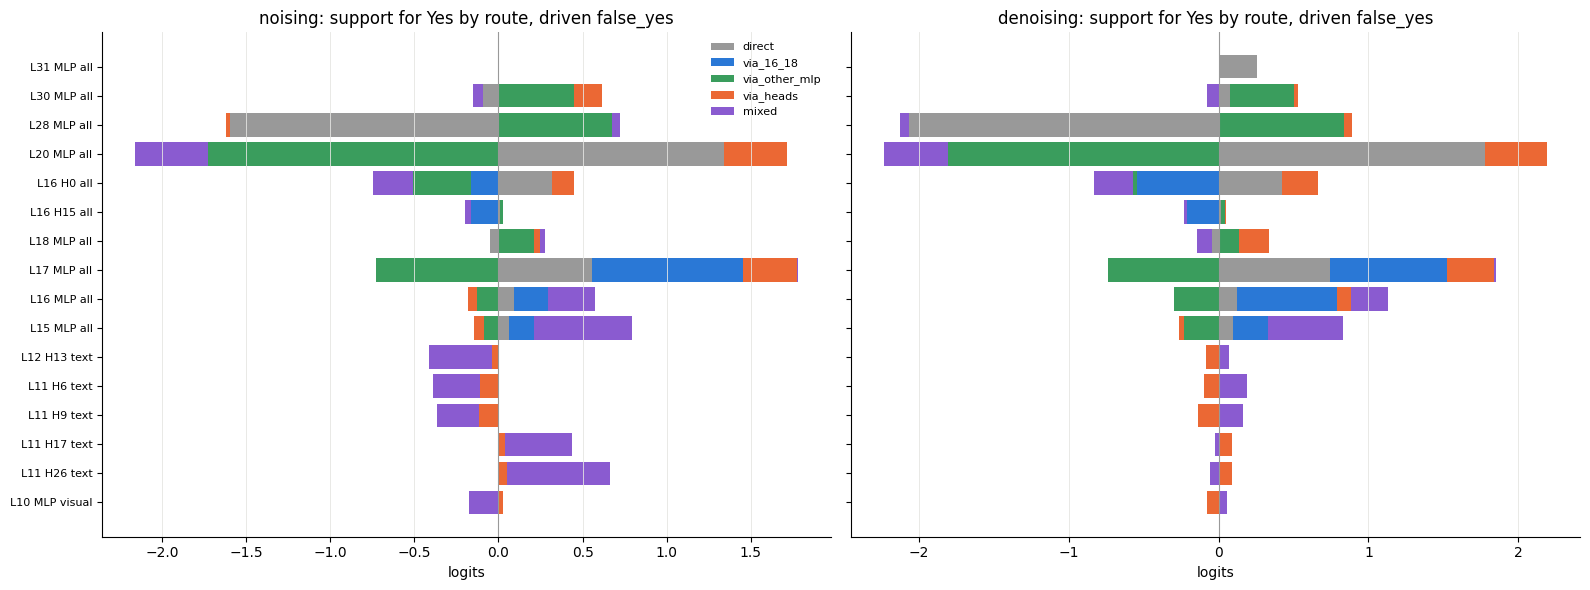

    [upload ok] summary


In [8]:
entries = []
for path in sorted(glob.glob(os.path.join(OUT_DIR, "P_batch_*.pt")), key=batch_number):
    entries.extend(torch.load(path))
good = [e for e in entries if e["ok"]]
assert len({e["question_id"] for e in good}) == len(good), "duplicated entries"
print(f"{len(entries)} entries, {len(good)} ok, {len(stage_ids) - len(good)} stage questions not done")

E = np.stack([e["effects"].numpy() for e in good])
sign = np.array([e["sign"] for e in good])
role = np.array([e["stratum"] for e in good])
uid = np.array([e["uid"] for e in good])
SUP = np.empty_like(E)
for di, dname in enumerate(DIRECTIONS):
    SUP[:, di] = (-sign if dname == "noising" else sign)[:, None, None] * E[:, di]
k = {n: i for i, n in enumerate(SET_NAMES)}


def routes(S):
    g = lambda name: S[..., k[name]]
    tot, dr = g("total"), g("direct")
    return {
        "total": tot, "direct": dr, "via_16_18": g("mlp_16_18") - dr, "via_15_20": g("mlp_15_20") - dr, "via_21_31": g("mlp_21_31") - dr,
        "via_other_mlp": g("mlp_all") - g("mlp_16_18"), "via_heads": g("heads_all") - dr, "mixed": tot - g("mlp_all") - g("heads_all") + dr,
        "not_16_18": tot - g("mlp_16_18"),
    }


R = routes(SUP)
fy = role == "false_yes"
ct = role == "true_yes"
print(f"false_yes {int(fy.sum())} questions, true_yes controls {int(ct.sum())}")
cols = ["total", "direct", "via_16_18", "via_other_mlp", "via_21_31", "via_heads", "mixed"]
for di, dname in enumerate(DIRECTIONS):
    table = pd.DataFrame({c: R[c][fy, di].mean(0) for c in cols}, index=SENDER_NAMES)
    table["share_16_18"] = table.via_16_18 / table.total.where(table.total.abs() > 0.02)
    print(f"--- {dname}: mean support for Yes carried by each sender on driven false_yes, split by route (logits) ---")
    print(table.round(3).to_string())

pairs = sorted(set(uid[fy]) & set(uid[ct]))
fy_ix = {u: i for i, u in enumerate(uid) if fy[i]}
ct_ix = {u: i for i, u in enumerate(uid) if ct[i]}
a_ix = np.array([fy_ix[u] for u in pairs])
b_ix = np.array([ct_ix[u] for u in pairs])
boot = np.random.default_rng(1).integers(0, len(pairs), size=(1000, len(pairs)))


def contrast(name, di):
    diff = R[name][a_ix, di] - R[name][b_ix, di]
    means = diff[boot].mean(1)
    return diff.mean(0), np.percentile(means, 2.5, axis=0), np.percentile(means, 97.5, axis=0)


print(f"--- false_yes minus matched true_yes over {len(pairs)} units: mean [95% interval over units] ---")
for di, dname in enumerate(DIRECTIONS):
    rows = {}
    for name in ["total", "via_16_18", "not_16_18", "via_heads"]:
        m, lo, hi = contrast(name, di)
        rows[name] = [f"{m[i]:+.3f} [{lo[i]:+.3f}, {hi[i]:+.3f}]" for i in range(len(SENDERS))]
    print(f"{dname}")
    print(pd.DataFrame(rows, index=SENDER_NAMES).to_string())

print("--- routers: does the promoter route (MLPs L16 to L18) and the rest each carry a separate effect? ---")
verdict = {}
for di, dname in enumerate(DIRECTIONS):
    for name in ROUTER_NAMES:
        i = SENDER_NAMES.index(name)
        mt, lt, ht = (x[i] for x in contrast("total", di))
        mp, lp, hp = (x[i] for x in contrast("via_16_18", di))
        mo, lo_, ho = (x[i] for x in contrast("not_16_18", di))
        prom = (lp > 0 or hp < 0) and abs(mp) >= 0.05
        rest = (lo_ > 0 or ho < 0) and abs(mo) >= 0.05
        verdict[f"{dname}/{name}"] = {"total": float(mt), "promoter": float(mp), "rest": float(mo), "promoter_route": bool(prom), "other_route": bool(rest)}
        print(f"{dname:10s} {name:14s} total {mt:+.3f} | promoter route {mp:+.3f} [{lp:+.3f}, {hp:+.3f}] {'present' if prom else 'absent'} | rest {mo:+.3f} [{lo_:+.3f}, {ho:+.3f}] {'present' if rest else 'absent'}")

BLUE, ORANGE, GREY, GREEN, PURPLE = "#2a78d6", "#eb6834", "#999999", "#3a9d5d", "#8a5bd0"
parts = [("direct", GREY), ("via_16_18", BLUE), ("via_other_mlp", GREEN), ("via_heads", ORANGE), ("mixed", PURPLE)]
fig, axes = plt.subplots(1, len(DIRECTIONS), figsize=(8 * len(DIRECTIONS), 6), sharey=True)
axes = np.atleast_1d(axes)
for di, dname in enumerate(DIRECTIONS):
    pos_ = np.zeros(len(SENDERS))
    neg_ = np.zeros(len(SENDERS))
    for name, color in parts:
        v = R[name][fy, di].mean(0)
        base_ = np.where(v >= 0, pos_, neg_)
        axes[di].barh(np.arange(len(SENDERS)), v, left=base_, color=color, label=name)
        pos_ += np.where(v >= 0, v, 0)
        neg_ += np.where(v < 0, v, 0)
    axes[di].set_yticks(np.arange(len(SENDERS)))
    axes[di].set_yticklabels(SENDER_NAMES, fontsize=8)
    axes[di].axvline(0, color=GREY, lw=0.8)
    axes[di].set_title(f"{dname}: support for Yes by route, driven false_yes")
    axes[di].set_xlabel("logits")
    axes[di].grid(color="#e5e5e2", lw=0.6, axis="x")
    axes[di].spines[["top", "right"]].set_visible(False)
axes[0].legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "path_routes.png"), dpi=150)
plt.show()

with open(os.path.join(OUT_DIR, "path_summary.json"), "w") as f:
    json.dump({
        "n_ok": len(good), "n_pairs": len(pairs), "verdict": verdict,
        "mean_routes_false_yes": {dname: {c: R[c][fy, di].mean(0).tolist() for c in R} for di, dname in enumerate(DIRECTIONS)},
        "sender_names": SENDER_NAMES,
    }, f)
if not upload("summary"):
    print(f"final upload failed; the batch files and summary are still in {OUT_DIR}, which is saved as this notebook's output")